# K-Means baseline

The baseline is K-Means with scikit learn's default settings except k = 5, fit on the full dataset prepared in 

| Section | Content |
|---|---|
| 1 | Setup and data |
| 2 | Baseline model and metrics |
| 3 | Cluster sizes and silhouette per cluster |
| 4 | What the clusters look like |
| 5 | PCA view |

## 1 Setup and data

In [41]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

darkjungle = "#1e201f"
mediumjungle = "#193a31"
deepgreen = "#1d6c61"
verdigris = "#3e89ab"
forestgreen = "#5aa371"
mist = "#e6eeeb"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.grid": True, "grid.color": mist, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.edgecolor": mediumjungle,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": darkjungle, "axes.labelcolor": darkjungle, "axes.titlecolor": mediumjungle,
    "xtick.color": mediumjungle, "ytick.color": mediumjungle,
    "axes.prop_cycle": plt.cycler(color=[deepgreen, verdigris, forestgreen, mediumjungle]),
})
# cluster colours: team palette plus lighter / darker tones of the same greens and blues
CLUSTER_COLORS = [deepgreen, verdigris, forestgreen, mediumjungle,
                  "#8cc3dd", "#a8d5b4", "#1f4e66", "#4fb3a3", "#7a9c8f", "#c9dcd5"]
div_cmap = LinearSegmentedColormap.from_list("div", [verdigris, "#ffffff", deepgreen])

IMG_DIR = "figs/kmeans"
os.makedirs(IMG_DIR, exist_ok=True)

def save(name):
    plt.savefig(f"{IMG_DIR}/{name}", dpi=150)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [42]:
data = pd.read_csv("H2_Cleaned_clustering.csv")
MODEL_COLS = list(data.columns)
X = data[MODEL_COLS].to_numpy()
info = pd.read_csv("H2_notdropped.csv")   # raw columns, same rows in the same order, only used to describe the clusters
assert len(info) == len(data)
print("bookings:", len(X), " model features:", len(MODEL_COLS))
print(MODEL_COLS)

bookings: 48990  model features: 12
['LeadTime', 'TotalNights', 'TotalOfSpecialRequests', 'ADR', 'TotalGuests', 'IsRepeatedGuest', 'Complementary', 'Corporate', 'Direct', 'Groups', 'Offline TA/TO', 'Online TA']


## 2 Baseline model and metrics

Everything except k is the library default , Only `random_state` is fixed so that the run can be repeated.

There is no train test split: clustering has no target to predict, so the clusters are judged directly with internal metrics (no labels involved):
* **Silhouette** (−1…1, higher is better): how much closer each booking is to its own cluster than to the next one.
* **Davies–Bouldin** (≥ 0, lower is better): average ratio of within cluster spread to between cluster distance(looks at pairs of clusters)
* **Calinski–Harabasz** (higher is better): betweencluster vs within-cluster dispersion (looks at all clusters together)
* **Inertia** (lower is better): total squared distance of every booking to its centroid

Silhouette needs every pairwise distance (O(n²)), so it is computed on a fixed random sample of 10,000 bookings. The other metrics use all bookings.

In [43]:
km = KMeans(n_clusters=5, random_state=RANDOM_STATE).fit(X)
labels = km.labels_

rng = np.random.default_rng(RANDOM_STATE)
S = np.sort(rng.choice(len(X), size=10_000, replace=False))     # silhouette sample

sizes = np.bincount(labels)
scores = pd.DataFrame([{
    "model": "K-Means baseline",
    "k": km.n_clusters,
    "silhouette": silhouette_score(X[S], labels[S]),
    "davies_bouldin": davies_bouldin_score(X, labels),
    "calinski_harabasz": calinski_harabasz_score(X, labels),
    "inertia": km.inertia_,
    "inertia_per_booking": km.inertia_ / len(X),
    "iterations": km.n_iter_,
}]).set_index("model")
scores.round(3)

,k,silhouette,davies_bouldin,calinski_harabasz,inertia,inertia_per_booking,iterations
model,,,,,,,
K-Means baseline,5,0.184,1.535,11070.558,135944.843,2.775,22


**Baseline result:** silhouette **0.184**, Davies–Bouldin **1.54**, Calinski–Harabasz **11,071**. The clusters exist, but they shade into each other rather than forming separate islands. That is typical for booking data, where lead time, price and stay length change gradually.

## 3 Cluster sizes and silhouette per cluster

The silhouette diagram shows every sampled booking's silhouette value, grouped by cluster. Wide, mostly positive blades are well-formed clusters. Values below 0 are bookings that sit closer to another cluster than to their own.

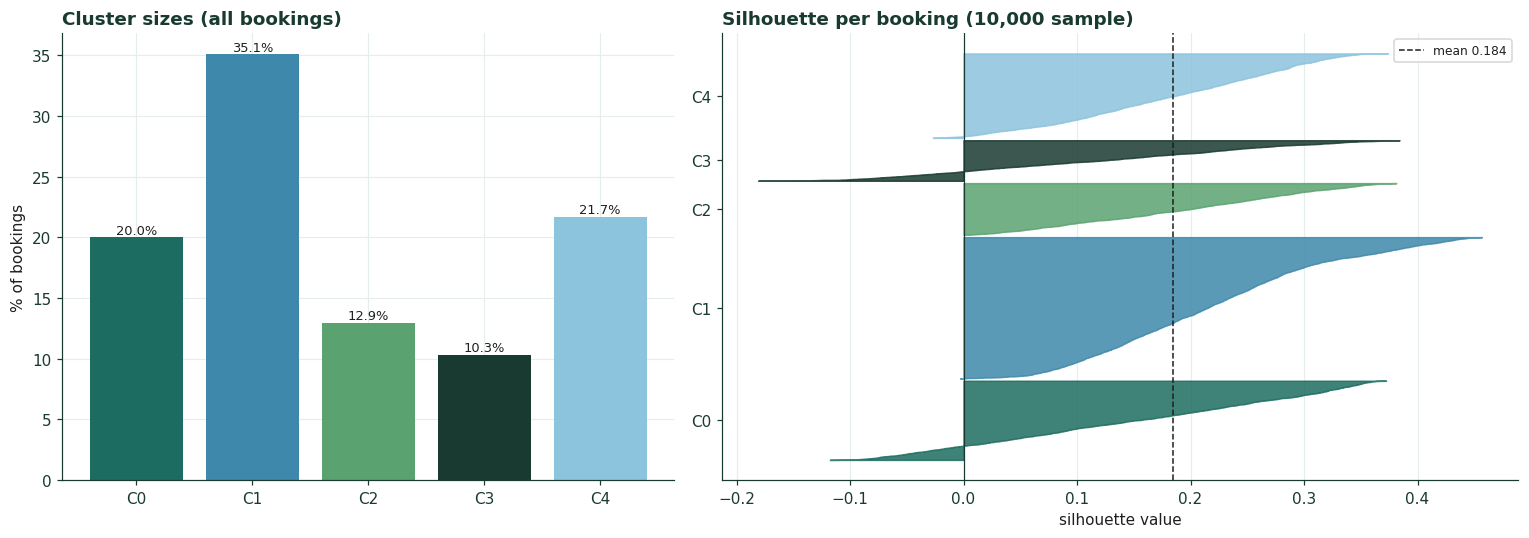

,bookings,share %,mean silhouette,% negative silhouette
cluster,,,,
0,9805,20.0,0.149,17.9
1,17177,35.1,0.221,0.0
2,6338,12.9,0.194,0.0
3,5046,10.3,0.118,23.6
4,10624,21.7,0.182,1.7


In [44]:
def silhouette_diagram(ax, X_s, labels_s, title):
    #perbooking silhouette values for each cluster
    vals = silhouette_samples(X_s, labels_s)
    y, ticks, names = 0, [], []
    for k in np.unique(labels_s):
        v = np.sort(vals[labels_s == k])
        ax.fill_betweenx(np.arange(y, y + len(v)), 0, v, color=CLUSTER_COLORS[k % len(CLUSTER_COLORS)], alpha=0.85)
        ticks.append(y + len(v) / 2); names.append(f"C{k}")
        y += len(v) + 60
    ax.axvline(0, color=mediumjungle, lw=0.8)
    ax.axvline(vals.mean(), color=darkjungle, ls="--", lw=1, label=f"mean {vals.mean():.3f}")
    ax.set_yticks(ticks, names); ax.set_xlabel("silhouette value"); ax.set_title(title); ax.legend(fontsize=8)
    ax.grid(axis="y", visible=False)
    return vals

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.3]})
share = sizes / len(X) * 100
bars = axes[0].bar([f"C{k}" for k in range(len(sizes))], share, color=CLUSTER_COLORS[:len(sizes)])
for b, v in zip(bars, share):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 0.3, f"{v:.1f}%", ha="center", fontsize=8.5)
axes[0].set_ylabel("% of bookings"); axes[0].set_title("Cluster sizes (all bookings)")

sil_vals = silhouette_diagram(axes[1], X[S], labels[S], "Silhouette per booking (10,000 sample)")
plt.tight_layout(); save("01_sizes_silhouette.png"); plt.show()

pd.DataFrame({"bookings": sizes, "share %": share.round(1),
              "mean silhouette": pd.Series(sil_vals).groupby(labels[S]).mean().round(3),
              "% negative silhouette": (pd.Series(sil_vals < 0).groupby(labels[S]).mean() * 100).round(1)},
             index=pd.Index(range(len(sizes)), name="cluster"))

* **C1** (35%, the largest) and **C2** are the cleanest clusters: highest mean silhouette (0.22 and 0.19) and no negative values. **C4** is close behind (1.7% negative).
* **C3** (24% negative) and **C0** (18% negative) are the weakest. Many of their bookings sit closer to a neighbouring cluster than to their own

## 4 What the clusters look like

**Centroids** in the scaled space (0 = average booking, ±1 = one standard deviation; segment columns are 0 to 0.71). They show which features define each cluster.

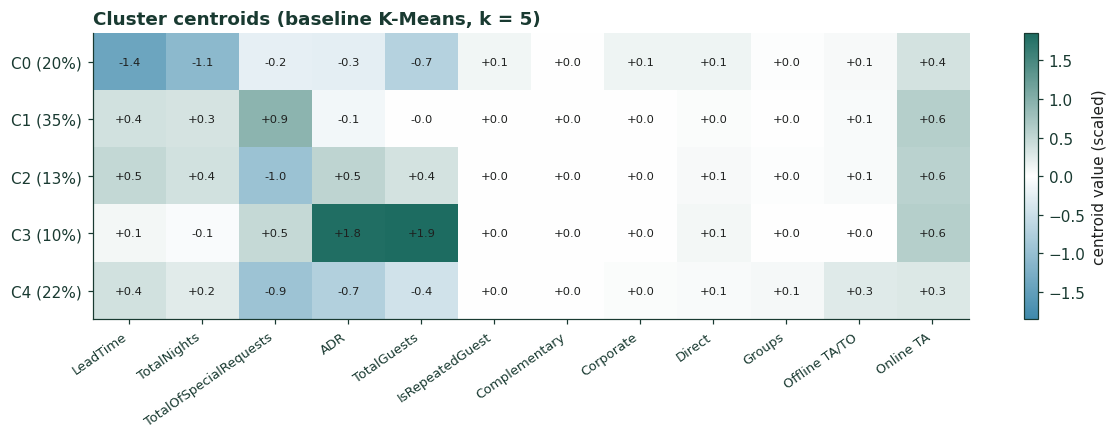

In [45]:
cent = pd.DataFrame(km.cluster_centers_, columns=MODEL_COLS, index=[f"C{k}" for k in range(km.n_clusters)])
fig, ax = plt.subplots(figsize=(11, 0.5 * len(cent) + 1.6))
lim = np.abs(cent.values).max()
im = ax.imshow(cent.values, cmap=div_cmap, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(cent.shape[1]), cent.columns, rotation=35, ha="right", fontsize=8.5)
ax.set_yticks(range(len(cent)), [f"{c} ({s:.0f}%)" for c, s in zip(cent.index, share)])
for i in range(cent.shape[0]):
    for j in range(cent.shape[1]):
        ax.text(j, i, f"{cent.values[i, j]:+.1f}", ha="center", va="center", fontsize=7.5)
ax.grid(False)
fig.colorbar(im, ax=ax, label="centroid value (scaled)")
ax.set_title("Cluster centroids (baseline K-Means, k = 5)")
plt.tight_layout(); save("02_centroid_heatmap.png"); plt.show()

In [46]:
prof = info.assign(cluster=labels).groupby("cluster").agg(
    lead_time_med=("LeadTime", "median"),
    nights_med=("TotalNights", "median"),
    guests_mean=("TotalGuests", "mean"),
    adr_med=("ADR", "median"),
    requests_mean=("TotalOfSpecialRequests", "mean"),
    main_segment=("Segment", lambda s: s.value_counts().index[0]),
    main_segment_pct=("Segment", lambda s: s.value_counts(normalize=True).iloc[0] * 100),
)
prof.insert(0, "share %", share)
prof["repeat_guest %"] = pd.Series(data["IsRepeatedGuest"].values).groupby(labels).mean() * 100
prof.round(1)

,share %,lead_time_med,nights_med,guests_mean,adr_med,requests_mean,main_segment,main_segment_pct,repeat_guest %
cluster,,,,,,,,,
0,20.0,3.0,1.0,1.5,98.0,0.5,Online TA,49.7,11.4
1,35.1,69.0,3.0,2.0,106.2,1.4,Online TA,84.6,0.4
2,12.9,88.0,3.0,2.3,130.0,0.0,Online TA,79.1,0.1
3,10.3,52.0,3.0,3.3,177.3,1.1,Online TA,84.4,0.2
4,21.7,69.0,3.0,1.7,85.0,0.0,Online TA,40.5,1.2


Reading the profiles:
* **C0 (20%):** **last-minute** (median 3 days), 1 night, 1.5 guests. The least Online TA (50%), the most Corporate and Direct bookings and **11% repeat guests**. Business and short trips. Cancels least (14%).
* **C1 (35%):** plan ahead (69 days), 3 nights, couples, through Online TA (85%), with the **most special requests** (1.4). 
* **C2 (13%):** plan ahead (88 days), 2.3 guests at €130 with **zero special requests**. Cancels most (57%).
* **C3 (10%):** **large parties** (3.3 guests, 52% with children) at the **highest rate** (median €177). Families.
* **C4 (22%):** plan ahead (69 days) at the **lowest rate** (median €85) with **zero special requests**. Many Offline TA/TO bookings (about 37%). Budget package bookings.

C1, C2 and C4 all plan ahead and stay 3 nights; they are split mainly by special requests (C1 vs C2/C4) and by price (C2 vs C4).

Two original features, LeadTime vs ADR, coloured by cluster on the 10k booking sample. 

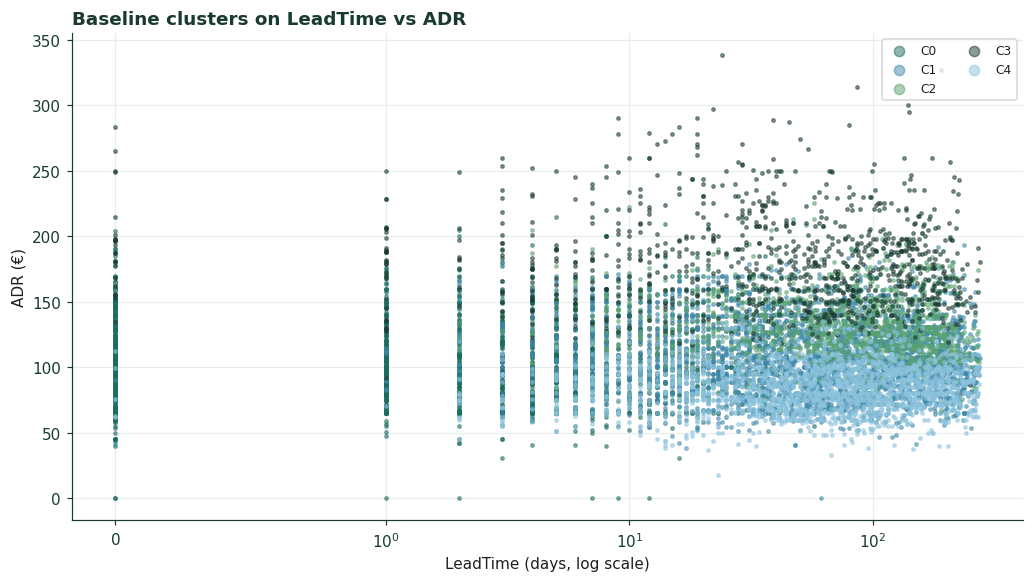

In [47]:
fig, ax = plt.subplots(figsize=(9.5, 5.4))
for k in range(km.n_clusters):
    m = labels[S] == k
    ax.scatter(info["LeadTime"].values[S][m], info["ADR"].values[S][m], s=5, alpha=0.5,
               color=CLUSTER_COLORS[k], label=f"C{k}")
ax.set_xscale("symlog", linthresh=1)
ax.set_xlabel("LeadTime (days, log scale)"); ax.set_ylabel("ADR (€)")
ax.set_title("Baseline clusters on LeadTime vs ADR")
ax.legend(markerscale=3, fontsize=8, ncol=2, loc="upper right")
plt.tight_layout(); save("03_leadtime_adr_scatter.png"); plt.show()

## 5 PCA view


PC1 33.2%, PC2 24.3%, together 57.5%


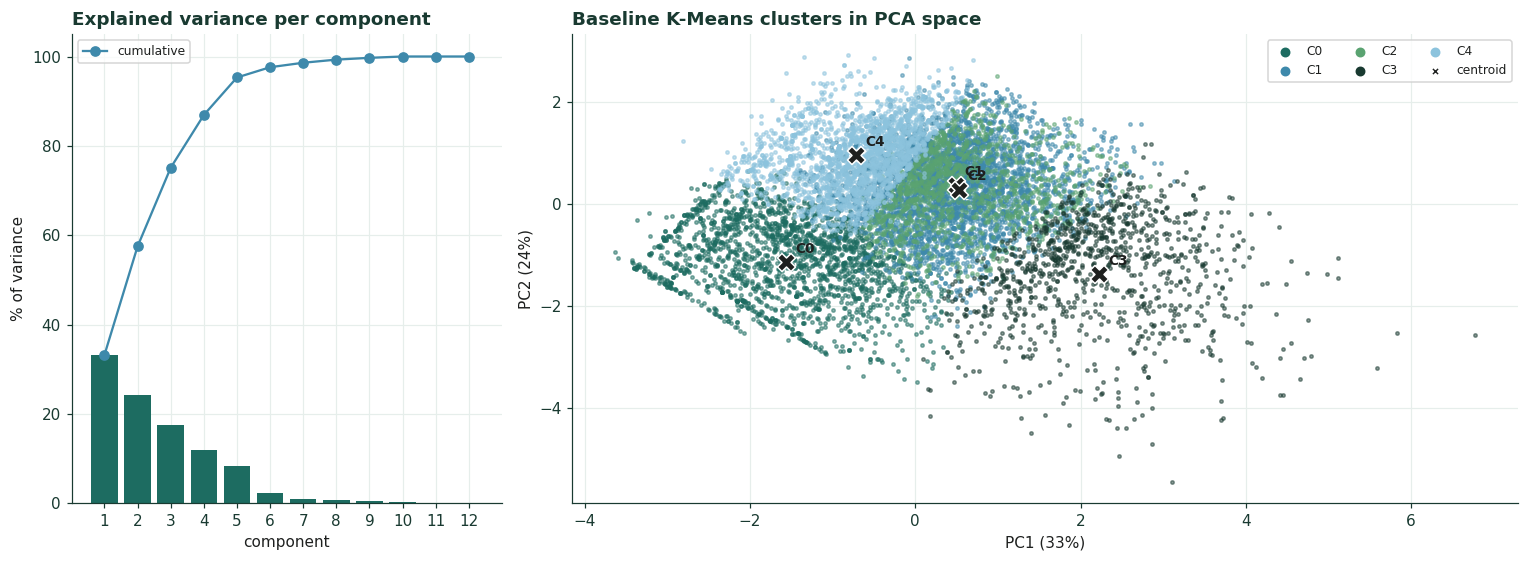

,PC1,PC2
TotalGuests,0.61,-0.24
ADR,0.51,-0.49
LeadTime,0.38,0.57
TotalNights,0.35,0.60
TotalOfSpecialRequests,0.30,-0.12
Online TA,0.10,-0.02
Corporate,-0.04,-0.01
IsRepeatedGuest,-0.03,-0.01
Offline TA/TO,-0.03,0.05
Groups,-0.01,0.01


In [48]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X)
var = pd.DataFrame({"explained %": pca_full.explained_variance_ratio_ * 100,
                    "cumulative %": np.cumsum(pca_full.explained_variance_ratio_) * 100},
                   index=[f"PC{i+1}" for i in range(X.shape[1])]).round(1)
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
P = pca.transform(X[S]); ev = pca.explained_variance_ratio_
print("PC1 {:.1%}, PC2 {:.1%}, together {:.1%}".format(ev[0], ev[1], ev.sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 2.2]})
ax = axes[0]
ax.bar(range(1, len(var) + 1), var["explained %"], color=deepgreen)
ax.plot(range(1, len(var) + 1), var["cumulative %"], "o-", color=verdigris, label="cumulative")
ax.set_xticks(range(1, len(var) + 1)); ax.set_xlabel("component"); ax.set_ylabel("% of variance")
ax.set_title("Explained variance per component"); ax.legend(fontsize=8)

ax = axes[1]
for k in range(km.n_clusters):
    m = labels[S] == k
    ax.scatter(P[m, 0], P[m, 1], s=5, alpha=0.5, color=CLUSTER_COLORS[k], label=f"C{k}")
c2 = pca.transform(km.cluster_centers_)
ax.scatter(c2[:, 0], c2[:, 1], marker="X", s=140, color=darkjungle, edgecolor="white", linewidth=1, label="centroid")
for k, (x, y) in enumerate(c2):
    ax.annotate(f"C{k}", (x, y), xytext=(6, 6), textcoords="offset points", fontsize=9, fontweight="bold")
ax.set_xlabel(f"PC1 ({ev[0]:.0%})"); ax.set_ylabel(f"PC2 ({ev[1]:.0%})")
ax.set_title("Baseline K-Means clusters in PCA space")
leg = ax.legend(fontsize=8, ncol=3, loc="upper right")
for h in leg.legend_handles:      # same marker size for clusters and centroid in the legend
    h.set_sizes([30]); h.set_alpha(1)
plt.tight_layout(); save("04_pca_clusters.png"); plt.show()

pd.DataFrame(pca.components_.T, index=MODEL_COLS, columns=["PC1", "PC2"]).round(2).sort_values("PC1", key=abs, ascending=False)

* The first two components keep **57.5%** of the variance. **PC1** is a "bigger and pricier" axis (TotalGuests 0.61, ADR 0.51). **PC2** contrasts planning ahead and long stays (LeadTime 0.57, TotalNights 0.60) with price (ADR −0.49).
* The last-minute cluster **C0** sits bottom-left and the large-party cluster **C3** on the right. **C1 and C2** land almost on top of each other, because they differ mainly on special requests, which load on later components.
* The diagonal stripes come from discrete values (1 night, 1 guest, 0 requests).